> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage0_overview_walkthrough_ko.ipynb`)](../ko/stage0_overview_walkthrough_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Starter README](../../README.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open the Starter demo](https://agentic-ontology-starter-115847445822.asia-northeast3.run.app/)
>
> **Lifecycle Navigation**: **[▶ 0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb)** → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# 0. End-to-End Entrypoint — Resource-Connected Starter Architecture & 5-Stage Agentic Ontology Walkthrough
## Ready-to-Use GCP Resource Connector (`OntologyResourceConnector`) + 3 Domain Business Tools (`DomainMcpServer`) · BigQuery Property Graph · ISO GQL

This master entrypoint notebook walks through the complete **Agentic Ontology Starter Pack v2.2.0** **Resource-Connected Starter Architecture** and methodology end to end. Heavy internal ontology builder pipelines are abstracted into the platform layer, while the Starter connects directly to **Ready-to-Use GCP Ontology Resources** (BigQuery `starter_ontology_dw` 10 tables, `STARTER_ONTOLOGY_GRAPH`, GCS 3-Layer OKF Wiki & `W1~W3` workflows, Cloud Spanner Graph) and exposes **4 Customizable Core Files** (`src/resource_connector.py`, `src/gcp_client.py`, `src/agent/mcp_server.py`, `src/agent/reasoning_engine.py`) and **3 Domain Business Tools**.

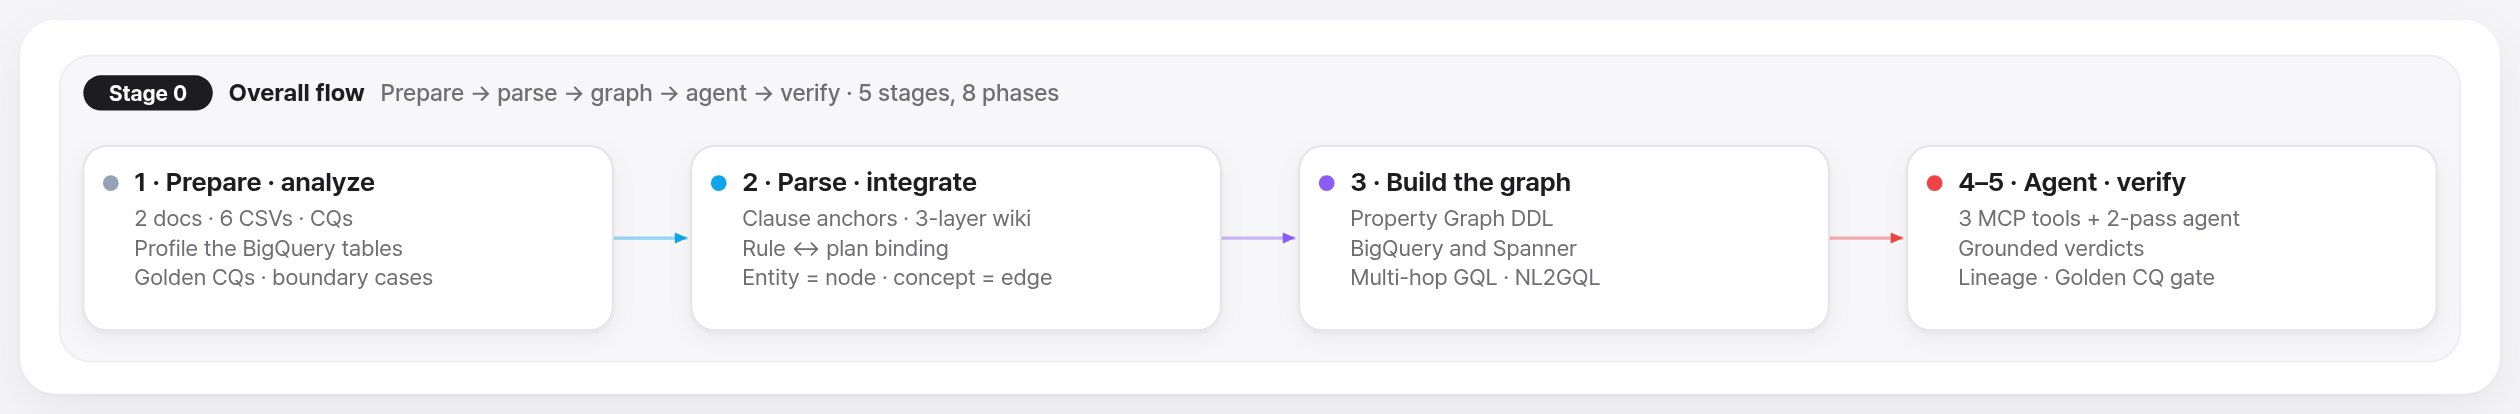

### 8-Phase Engineering Flow & Bilingual Notebook Navigation Map (`notebooks/ko/` · `notebooks/en/`)

| Engineering Phase | Canonical Stage | Exposed Modules & Resource Tools | Intermediate Data, Tables & Graph Schematics | Korean Notebook (`ko/`) | English Notebook (`en/`) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1. Prepare**<br>**2. Analyze** | **Stage 1**<br>(`Step 1.1`–`1.2`) | `src/resource_connector.py`<br>`stage1_resource_check`<br>`H.check_cq_sql()` | Raw CSV/MD inventory, 10-table ER blueprint, de-identified contracts, subsidy heatmap, 5 Golden CQs SQL check | [`stage1_ko`](../ko/stage1_asset_and_cq_ko.ipynb) | [`stage1_en`](./stage1_asset_and_cq_en.ipynb) |
| **3. Parse**<br>**4. Integrate** | **Stage 2**<br>(`Step 2.1`–`2.2`) | `src/resource_connector.py`<br>`stage2_resource_check`<br>`H.propose_triples()` | `DOC_CHUNK` SHA-256 anchor table, 3-Layer OKF Wiki, 4 Business Rules & 3 Workflows (`W1~W3`), Semantic Graph schematic | [`stage2_ko`](../ko/stage2_wiki_and_semantic_graph_ko.ipynb) | [`stage2_en`](./stage2_wiki_and_semantic_graph_en.ipynb) |
| **5. Build Graph** | **Stage 3**<br>(`Step 3.1`–`3.2`) | `src/gcp_client.py`<br>`stage3_resource_check`<br>`H.run_gql()` / `H.nl2gql()` | 6 Node × 4 Edge metamodel schematic, BQ/Spanner DDL, full topology & 1..2-hop ego graph, parameterized ISO GQL | [`stage3_ko`](../ko/stage3_property_graph_bigquery_spanner_ko.ipynb) | [`stage3_en`](./stage3_property_graph_bigquery_spanner_en.ipynb) |
| **6. Build Agent**<br>**7. Answer** | **Stage 4**<br>(`Step 4.1`–`4.2`) | `src/agent/mcp_server.py`<br>`src/agent/reasoning_engine.py` | Code exposure boundary (4 core files), 3 Domain Business Tools catalog, AI FDE (`Gate G2-W`) orchestration, 180d penalty curve | [`stage4_ko`](../ko/stage4_agent_and_mcp_execution_ko.ipynb) | [`stage4_en`](./stage4_agent_and_mcp_execution_en.ipynb) |
| **8. Verify & Gate** | **Stage 5**<br>(`Step 5.1`–`5.2`) | `src/lineage_service.py`<br>`stage5_resource_check`<br>`H.recheck_cq()` | 6-Layer enterprise lineage DAG, live CQ re-audit, Boundary 50-trial metrics & Gate 1..5 checklist | [`stage5_ko`](../ko/stage5_lineage_and_evaluation_ko.ipynb) | [`stage5_en`](./stage5_lineage_and_evaluation_en.ipynb) |

### 3-Track Selective Adoption Model (`config/starter_config.json`)

| Track | Active Stages | Graph Engine | Target Scenario |
| :--- | :--- | :--- | :--- |
| **Track 1 · Lite** | `Stage 1 → Stage 2 → Stage 4` | `none` | Source documents only, no customer tables. Source chunks build the document-based Wiki; the agent receives all `tb_doc_chunks` rows as context and answers with chunk ID citations; citation CQs are scored |
| **Track 2 · Standard** | `Stage 1 → Stage 2 → Stage 3 → Stage 4` | `bigquery` / `spanner` | Unifying 4 structured DW ledgers and unstructured rules into a Zero-ETL Property Graph for multi-hop ISO GQL |
| **Track 3 · Full-Stack** | `Stage 1 → Stage 2 → Stage 3 → Stage 4 → Stage 5` | `bigquery` | Full lifecycle operation including end-to-end lineage, 5 Golden CQs, 50-trial boundary benchmark, and Cloud Run release gates |


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 0. [Resource-Connected Architecture & Code Exposure Boundary] Reference Studio Hub, 4 Exposed Core Files & Stage 0~5 Unified Map (`OntologyResourceConnector`)


In [ ]:
from src.resource_connector import REFERENCE_STUDIOS, CODE_EXPOSURE_BOUNDARY, STAGE_UNIFIED_MAP
H.show(pd.DataFrame(list(REFERENCE_STUDIOS.values()))[["id", "name_ko" if H.LANG == "ko" else "name_en", "tabs", "domain", "url"]])
H.show(pd.DataFrame(CODE_EXPOSURE_BOUNDARY["exposed_starter_layer"])[["file", "category", "role_ko" if H.LANG == "ko" else "role_en"]])
H.show(pd.DataFrame(STAGE_UNIFIED_MAP)[["stage", "starter_tab", "process_flow", "ready_resource", "notebook_ko" if H.LANG == "ko" else "notebook_en"]])


### 1. [Architecture Blueprint] 8-Phase Engineering Pipeline & 10-Table Schema Blueprint


In [ ]:
H.draw_eight_phase_flow()
H.draw_table_er_blueprint()


### 2. [Phase 1–2 · Stage 1: Prepare & Analyze] Raw Input Inventory & BigQuery 10-Table Profiling (`stage1_resource_check` + `%%bqsql`)


In [ ]:
H.show(H.raw_inputs_inventory())
res_s1 = server.execute_tool("stage1_resource_check")
H.show_tool(res_s1)


In [ ]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN '3_edge_bridge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN '2_knowledge_wiki'
       ELSE '1_structured_master' END AS table_role
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY table_role, table_id


In [ ]:
H.show(df_tables)
H.bar(df_tables, "table_id", "row_count", "Row Count across 10 Tables in starter_ontology_dw", horizontal=True)


### 3. [Phase 3–4 · Stage 2: Parse & Integrate] SHA-256 Guide Chunking, 3-Layer Wiki Compilation & Semantic Ontology Schematic


In [ ]:
H.show(H.parse_guides_live_demo())
df_wiki, manifest = H.wiki_compilation_summary()
H.show(df_wiki)
res_s2 = server.execute_tool("stage2_resource_check")
H.show_tool(res_s2, "anchored_chunks")
H.draw_semantic_design_graph()


### 4. [Phase 5 · Stage 3: Build Property Graph] `STARTER_ONTOLOGY_GRAPH` Metamodel, Executed GQL & Bound Variables, and Full Topology (`%%bqsql` + `H.run_gql`)


In [ ]:
res_s3 = server.execute_tool("stage3_resource_check")
H.show_tool(res_s3, "node_tables")
H.draw_property_graph_metamodel()


In [ ]:
%%bqsql df_paths
GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH p = (a)-[e]->(b)
RETURN TO_JSON(p) AS path


In [ ]:
gql_cust_rules = """GRAPH `seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode),
      (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode),
      (ch:DocChunkNode)
WHERE c.customer_id = 'CUST_DEMO_001' AND ch.chunk_id = ap.source_chunk_id
RETURN c.customer_id AS customer_id, d.device_name AS device_name, p.plan_name AS plan_name,
       r.rule_id AS rule_id, ap.source_chunk_id AS chunk_id, ch.content_sha256 AS sha256_anchor
ORDER BY r.rule_id"""
_ = H.run_gql(
    gql_cust_rules,
    variables={
        "GRAPH": ("seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH", "Target BigQuery Property Graph"),
        "c.customer_id": ("'CUST_DEMO_001'", "CustomerContractNode filter parameter"),
        "ch.chunk_id": ("ap.source_chunk_id", "DocChunkNode SHA-256 anchor join key"),
    },
    title="3-Hop ISO GQL Execution (Customer Contract → Device/Plan ← Domain Rule + DocChunk)",
)
nodes, edges = H.paths_to_graph(H.pdf(df_paths)["path"])
H.md(f"**Extracted physical graph nodes: `{len(nodes)}` · edges: `{len(edges)}`**")
H.draw_graph(nodes, edges, "Full Instance Topology of STARTER_ONTOLOGY_GRAPH (5-Column Layered Layout)", legend=H.LABEL_COLORS)


### 5. [Phase 6–7 · Stage 4: Build Agent & Answer] 2-Pass Agent Blueprint, Live NL-to-GQL & Golden CQ Execution


In [ ]:
H.draw_agent_architecture()
node_labels, edge_labels, _ = H.graph_metadata()
schema_str = H.schema_text(node_labels, edge_labels)
_ = H.nl2gql("Show each customer's device name, subscribed plan name, and monthly fee ordered by customer ID", schema_str)
H.show_agent(agent.execute_cycle('If customer CUST_DEMO_001 downgrades to 5G Light (37,000 KRW) on day 120, what is the penalty and grounded anchor?'),
             "Golden CQ-03 · 120-Day Prorated Penalty Calculation")
H.show_agent(agent.execute_cycle('If customer CUST_DEMO_003 (Senior Welfare Eligible) switches to a senior plan on day 88, is the penalty exempted and what is the graph path?'),
             "Golden CQ-05 · Senior Welfare Exemption & Multi-Hop Graph Path")


### 6. [Phase 8 · Stage 5: Verify & Release Gate] End-to-End Lineage Summary & Gate 1–5 Readiness Verdict


In [ ]:
res_s5 = server.execute_tool("stage5_resource_check")
H.show_tool(res_s5)
H.show(H.gate_checklist_table())


### Q&A
- **Q.** How do structured DW tables and unstructured policy documents connect to produce grounded agent answers?
  - **A.** Through the 8-phase engineering pipeline (Prepare → Analyze → Parse → Integrate → Build Graph → Build Agent → Answer → Verify), 6 CSVs and 2 Markdown guides are unified into Ready-to-Use GCP resources—10 BigQuery tables (`starter_ontology_dw`), a 3-Layer LLM-Wiki (`W1~W3`), and `STARTER_ONTOLOGY_GRAPH` (25 nodes, 29 edges)—connected via `OntologyResourceConnector` and queried by the 3 Domain Business Tools (`DomainMcpServer`) and 2-Pass Gemini (`gemini-4-argon`, `Gate G2-W`) agent.

### Data Analysis Key Findings
- Verified 10 BigQuery tables (62 total rows across 4 master, 2 knowledge, and 4 edge tables) with 0 de-identification violations (`CUST_DEMO_001~006`).
- All 5 policy chunks (`DOC_CHUNK_001~005`) match their stored SHA-256 anchors in `tb_doc_chunks`, with 0 duplicate keys and verified multi-hop paths in `STARTER_ONTOLOGY_GRAPH`.
- Latest reports: Golden CQ 5/5 (`100.0%`, 2026-09-30) and `96.0%` average success across 50 boundary trials (2026-09-27). The Gate 1–5 verdict follows the measured table above.

### Insights or Next Steps
- Proceed to the `Stage 1 (Prepare & Analyze)` notebook to inspect the raw CSV/guide schema design, data profiling, and Golden CQ verification SQL in detail.

---
> **Next Navigation**: [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) ｜ [🌐 Korean Version](../ko/stage0_overview_walkthrough_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/METHODOLOGY_EN.md)
